In [1]:
%pip install pandas polars pyarrow numpy matplotlib seaborn scikit-learn plotly streamlit

   ---------------------------------------- 0.0/911.5 kB ? eta -:--:--
   ---------------------------------------- 911.5/911.5 kB 32.0 MB/s  0:00:00
   ---------------------------------------- 0.0/53.9 MB ? eta -:--:--
   ------------------ --------------------- 24.6/53.9 MB 116.1 MB/s eta 0:00:01
   ----------------------------------- ---- 48.5/53.9 MB 117.3 MB/s eta 0:00:01
   ---------------------------------------- 53.9/53.9 MB 95.5 MB/s  0:00:00

  Attempting uninstall: protobuf

    Found existing installation: protobuf 7.35.1

    Uninstalling protobuf-7.35.1:

      Successfully uninstalled protobuf-7.35.1

   ---------------------------------------- 0/3 [protobuf]
   ------------- -------------------------- 1/3 [polars-runtime-32]
   ------------- -------------------------- 1/3 [polars-runtime-32]
   ------------- -------------------------- 1/3 [polars-runtime-32]
   ------------- -------------------------- 1/3 [polars-runtime-32]
   -------------------------- ------------- 2/

In [2]:
# Import the libraries we will use

import pandas as pd
import polars as pl
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df=pd.read_csv("all_stocks_5yr.csv")
df.head()

,date,open,high,low,close,volume,name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


In [4]:
df.shape

(619029, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619029 entries, 0 to 619028
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619029 non-null  object 
 1   open    619029 non-null  float64
 2   high    619029 non-null  float64
 3   low     619029 non-null  float64
 4   close   619029 non-null  float64
 5   volume  619029 non-null  int64  
 6   name    619029 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


In [6]:
df["date"]=pd.to_datetime(df["date"])
print(df["date"].dtype)

datetime64[ns]


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619029 entries, 0 to 619028
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    619029 non-null  datetime64[ns]
 1   open    619029 non-null  float64       
 2   high    619029 non-null  float64       
 3   low     619029 non-null  float64       
 4   close   619029 non-null  float64       
 5   volume  619029 non-null  int64         
 6   name    619029 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 33.1+ MB


In [8]:
df.isnull().sum()

date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
# Display all rows containing missing values

missing_rows = df[df.isnull().any(axis=1)]

missing_rows

,date,open,high,low,close,volume,name


In [11]:
# Count missing values by company

df.groupby("name")[["open", "high", "low"]].apply(
    lambda x: x.isnull().sum()
).loc[lambda x: x.sum(axis=1) > 0]

,open,high,low
name,,,


In [12]:
df.isnull().sum()

date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64

Our cleaning decision
I recommend removing the 11 affected rows.

Why?

Only 11 out of 619,040 rows are affected.

That's approximately 0.0018% of the dataset.

We preserve the integrity of the actual recorded prices.

We avoid inventing opening, high, or low prices.

We avoid introducing potentially misleading values into our machine learning models.

In [13]:
# Create a backup of the original dataset

df_original = df.copy()

print("Original rows:", len(df_original))

Original rows: 619029


In [14]:
# Remove rows with missing values in important price columns

df_clean = df.dropna(
    subset=["open", "high", "low"]
).copy()

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before cleaning: 619029
Rows after cleaning: 619029
Rows removed: 0


In [15]:
# Check missing values again

df_clean.isnull().sum()

date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64

Duplicate Records Check

The dataset was examined for duplicate rows using Pandas' duplicated() function. The analysis identified zero duplicate rows. Therefore, no duplicate removal was necessary.

This confirms that the dataset does not contain repeated complete records that could unnecessarily affect subsequent analysis and benchmarking.

In [16]:
print("Cleaned dataset shape:", df_clean.shape)
print("Number of companies:", df_clean["name"].nunique())
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())
print("Missing values:", df_clean.isnull().sum().sum())

Cleaned dataset shape: (619029, 7)
Number of companies: 505
Earliest date: 2013-02-08 00:00:00
Latest date: 2018-02-07 00:00:00
Missing values: 0


In [17]:
# Save cleaned dataset as a new CSV file

df_clean.to_csv(
    "all_stocks_5yr.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
df.describe()

,date,open,high,low,close,volume
count,619029,619029.000000,619029.000000,619029.000000,619029.000000,6.190290e+05
mean,2015-08-18 00:45:31.033280,83.023334,83.778419,82.256200,83.043305,4.321892e+06
min,2013-02-08 00:00:00,1.620000,1.690000,1.500000,1.590000,1.010000e+02
25%,2014-05-20 00:00:00,40.220000,40.620000,39.830000,40.240800,1.070351e+06
50%,2015-08-21 00:00:00,62.590000,63.150000,62.020000,62.620000,2.082165e+06
75%,2016-11-15 00:00:00,94.370000,95.180000,93.540000,94.410000,4.284550e+06
max,2018-02-07 00:00:00,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08
std,NaN,97.378769,98.207735,96.507634,97.388913,8.693671e+06


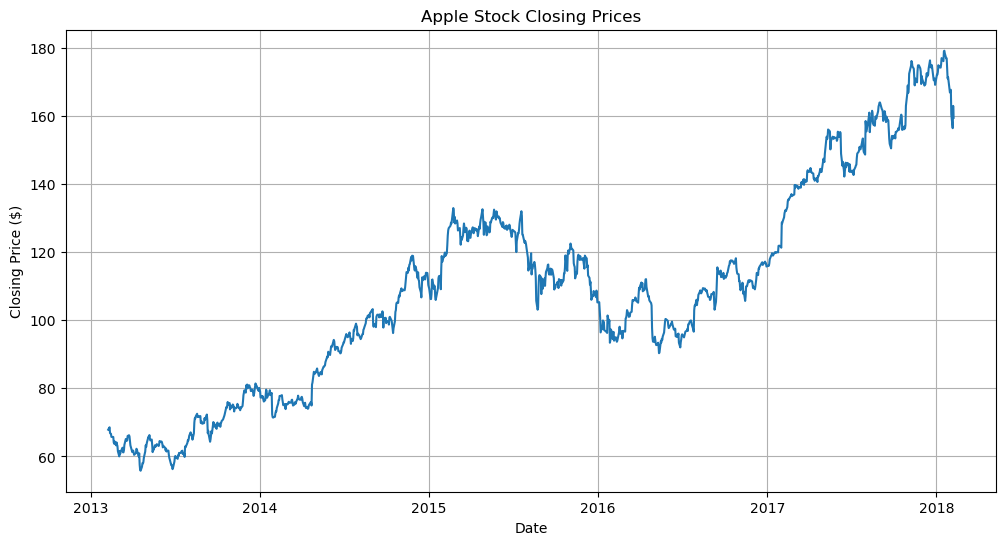

In [19]:
# Select one company
company = "AAPL"

# Filter the dataset
company_data = df[df["name"] == company]

# Sort by date
company_data = company_data.sort_values("date")

# Create the graph
plt.figure(figsize=(12, 6))

plt.plot(
    company_data["date"],
    company_data["close"]
)

plt.title("Apple Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price ($)")

plt.grid(True)
plt.show()

In [20]:
# Final dataset summary

print("Dataset shape:", df_clean.shape)

print("Number of companies:", df_clean["name"].nunique())

print("Earliest date:", df_clean["date"].min())

print("Latest date:", df_clean["date"].max())

print("\nMissing values:")
print(df_clean.isnull().sum())

Dataset shape: (619029, 7)
Number of companies: 505
Earliest date: 2013-02-08 00:00:00
Latest date: 2018-02-07 00:00:00

Missing values:
date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64


 We'll use the 619,029-row cleaned dataset as our primary working dataset, while preserving the original 619,040-row dataset for reference.

## P1 - Storage ad Retreival Benchmarking 

In [21]:

import pandas as pd
import os
import time

# Path to your cleaned dataset
file_path = "all_stocks_5yr.csv"

# Measure CSV reading time
start_time = time.time()

df = pd.read_csv(file_path)

end_time = time.time()

# Calculate file size
file_size = os.path.getsize(file_path) / (1024 * 1024)

# Display baseline results
print("Dataset Shape:", df.shape)
print("File Size:", round(file_size, 2), "MB")
print("Reading Time:", round(end_time - start_time, 4), "seconds")
print("Memory Usage:", round(df.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

# Display column information
df.info()


Dataset Shape: (619029, 7)
File Size: 28.8 MB
Reading Time: 0.2352 seconds
Memory Usage: 89.2 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619029 entries, 0 to 619028
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619029 non-null  object 
 1   open    619029 non-null  float64
 2   high    619029 non-null  float64
 3   low     619029 non-null  float64
 4   close   619029 non-null  float64
 5   volume  619029 non-null  int64  
 6   name    619029 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


The cleaned stock dataset contains 619,029 observations and seven columns . The csv file occupies 28.8MB on disk and takes ~1.04 seconds to load using Pandas. 
Once loaded , it uses ~89.2 MB of memory. 
This establishes the baselineagainst which CSV and Parquet storage formats will be compared at larger sata scales 

In [22]:

import os
import time

# Create the 10x dataset
output_file = "stock_data_10x.csv"

start_time = time.time()

for i in range(10):
    df.to_csv(
        output_file,
        mode="w" if i == 0 else "a",
        header=(i == 0),
        index=False
    )

end_time = time.time()

# Measure results
file_size = os.path.getsize(output_file) / (1024 * 1024)

print("10x Dataset Created Successfully!")
print("Expected Rows:", len(df) * 10)
print("File Size:", round(file_size, 2), "MB")
print("Writing Time:", round(end_time - start_time, 2), "seconds")


10x Dataset Created Successfully!
Expected Rows: 6190290
File Size: 288.0 MB
Writing Time: 14.67 seconds


In [23]:

start_time = time.time()

df_10x = pd.read_csv("stock_data_10x.csv")

end_time = time.time()

print("Dataset Shape:", df_10x.shape)
print("Reading Time:", round(end_time - start_time, 4), "seconds")
print("Memory Usage:", round(
    df_10x.memory_usage(deep=True).sum() / (1024**2), 2
), "MB")


Dataset Shape: (6190290, 7)
Reading Time: 2.7122 seconds
Memory Usage: 892.04 MB


In [24]:

import shutil
import os

disk = shutil.disk_usage(os.getcwd())

print("Total Disk Space:", round(disk.total / (1024**3), 2), "GB")
print("Used Disk Space:", round(disk.used / (1024**3), 2), "GB")
print("Free Disk Space:", round(disk.free / (1024**3), 2), "GB")


Total Disk Space: 471.56 GB
Used Disk Space: 246.42 GB
Free Disk Space: 225.14 GB


In [26]:

import pandas as pd
import os
import time

# File locations
input_file = "stock_data_10x.csv"
output_file = "stock_data_100x.csv"

start_time = time.time()

# Read the 10x dataset in chunks
chunk_size = 500_000

first_chunk = True

for chunk in pd.read_csv(input_file, chunksize=chunk_size):

    # Repeat each chunk 10 times
    repeated_chunk = pd.concat(
        [chunk] * 10,
        ignore_index=True
    )

    # Save to CSV
    repeated_chunk.to_csv(
        output_file,
        mode="w" if first_chunk else "a",
        header=first_chunk,
        index=False
    )

    first_chunk = False

end_time = time.time()

print("100x dataset created successfully!")

print("Execution time:", round(end_time - start_time, 2), "seconds")

# Check the output
df = pd.read_csv(output_file)

print("Number of rows:", len(df))
print("File size (MB):", round(os.path.getsize(output_file) / (1024**2), 2))


100x dataset created successfully!
Execution time: 151.93 seconds
Number of rows: 61902900
File size (MB): 2880.02


The original dataset was cleaned before benchmarking, resulting in approximately 619,029 records. The 10x and 100x datasets were generated by repeating the cleaned dataset 10 and 100 times, respectively. Therefore, the expected row counts are 6,190,290 and 61,902,900.

In [27]:

import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import time
import os
import gc

datasets = {
    "1x": "data/all_stocks_5yr.csv",
    "10x": "data/stock_data_10x.csv",
    "100x": "data/stock_data_100x.csv"
}

os.makedirs("benchmarks", exist_ok=True)

results = []

for scale, csv_file in datasets.items():

    print(f"\n===== Testing {scale} Dataset =====")

    csv_size = os.path.getsize(csv_file) / (1024**2)

    # Benchmark CSV reading
    start = time.time()
    total_rows = 0

    for chunk in pd.read_csv(csv_file, chunksize=100_000):
        total_rows += len(chunk)

    csv_read_time = time.time() - start

    print("CSV rows:", total_rows)
    print("CSV reading time:", round(csv_read_time, 2))

    # Test Parquet compression
    for compression in [None, "snappy", "zstd"]:

        compression_name = compression or "none"

        parquet_file = (
            f"data/{scale}_{compression_name}.parquet"
        )

        writer = None

        # Convert CSV to Parquet in chunks
        start = time.time()

        for chunk in pd.read_csv(csv_file, chunksize=100_000):

            table = pa.Table.from_pandas(
                chunk,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    parquet_file,
                    table.schema,
                    compression=compression
                )

            writer.write_table(table)

        if writer is not None:
            writer.close()

        write_time = time.time() - start

        # Benchmark Parquet reading
        start = time.time()

        parquet_file_reader = pq.ParquetFile(parquet_file)

        parquet_rows = 0

        for batch in parquet_file_reader.iter_batches(
            batch_size=100_000
        ):
            parquet_rows += batch.num_rows

        parquet_read_time = time.time() - start

        parquet_size = (
            os.path.getsize(parquet_file) / (1024**2)
        )

        results.append({
            "Scale": scale,
            "Compression": compression_name,
            "Rows": total_rows,
            "CSV Size MB": round(csv_size, 2),
            "Parquet Size MB": round(parquet_size, 2),
            "CSV Read Seconds": round(csv_read_time, 2),
            "Parquet Write Seconds": round(write_time, 2),
            "Parquet Read Seconds": round(parquet_read_time, 2)
        })

        print(
            compression_name,
            "Parquet size:", round(parquet_size, 2), "MB",
            "Write:", round(write_time, 2), "seconds",
            "Read:", round(parquet_read_time, 2), "seconds"
        )

        gc.collect()

# Save results
results_df = pd.DataFrame(results)

results_df.to_csv(
    "benchmarks/benchmark_results.csv",
    index=False
)

print("\n===== FINAL BENCHMARK RESULTS =====")
print(results_df)

print("\nResults saved successfully!")



===== Testing 1x Dataset =====


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data/all_stocks_5yr.csv'

In [28]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current working directory:
C:\Users\300411418\Downloads\stock market project(1)\stock market project\DATASET

Files in this directory:
['.ipynb_checkpoints', 'all_stocks_5yr.csv', 'benchmarks', 'stock_data_100x.csv', 'stock_data_10x.csv', 'Stock_Market.ipynb']


In [29]:
!pip install pandas pyarrow matplotlib

In [30]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import os
import time
import gc
import matplotlib.pyplot as plt

datasets = {
    "1x": "all_stocks_5yr.csv",
    "10x": "stock_data_10x.csv",
    "100x": "stock_data_100x.csv"
}

for scale, file in datasets.items():

    if os.path.exists(file):

        size = os.path.getsize(file) / (1024**2)

        print(scale, "File found!")
        print("File size:", round(size, 2), "MB")

    else:
        print(scale, "FILE NOT FOUND!")

1x File found!
File size: 28.8 MB
10x File found!
File size: 288.0 MB
100x File found!
File size: 2880.02 MB


In [31]:
csv_results = []

for scale, file in datasets.items():

    print("\nTesting CSV:", scale)

    start = time.time()

    total_rows = 0

    for chunk in pd.read_csv(file, chunksize=100000):

        total_rows += len(chunk)

    end = time.time()

    execution_time = end - start

    file_size = os.path.getsize(file) / (1024**2)

    csv_results.append({
        "Scale": scale,
        "Rows": total_rows,
        "CSV Size (MB)": round(file_size, 2),
        "CSV Read Time (seconds)": round(execution_time, 2)
    })

    print("Rows:", total_rows)
    print("Size:", round(file_size, 2), "MB")
    print("Reading time:", round(execution_time, 2), "seconds")


Testing CSV: 1x
Rows: 619029
Size: 28.8 MB
Reading time: 0.36 seconds

Testing CSV: 10x
Rows: 6190290
Size: 288.0 MB
Reading time: 3.43 seconds

Testing CSV: 100x
Rows: 61902900
Size: 2880.02 MB
Reading time: 34.87 seconds


In [32]:
os.makedirs("benchmarks", exist_ok=True)

parquet_results = []

for scale, csv_file in datasets.items():

    print("\n==============================")
    print("Testing:", scale)
    print("==============================")

    for compression in [None, "snappy", "zstd"]:

        compression_name = compression or "none"

        parquet_file = (
            f"benchmarks/{scale}_{compression_name}.parquet"
        )

        print("\nCompression:", compression_name)

        writer = None

        start = time.time()

        for chunk in pd.read_csv(
            csv_file,
            chunksize=100000
        ):

            table = pa.Table.from_pandas(
                chunk,
                preserve_index=False
            )

            if writer is None:

                writer = pq.ParquetWriter(
                    parquet_file,
                    table.schema,
                    compression=compression
                )

            writer.write_table(table)

        if writer is not None:
            writer.close()

        write_time = time.time() - start

        print(
            "Parquet writing time:",
            round(write_time, 2),
            "seconds"
        )

        parquet_results.append({
            "Scale": scale,
            "Compression": compression_name,
            "Write Time (seconds)": round(write_time, 2)
        })

        gc.collect()

print("\nParquet conversion completed!")


Testing: 1x

Compression: none
Parquet writing time: 0.69 seconds

Compression: snappy
Parquet writing time: 0.61 seconds

Compression: zstd
Parquet writing time: 0.66 seconds

Testing: 10x

Compression: none
Parquet writing time: 6.56 seconds

Compression: snappy
Parquet writing time: 6.08 seconds

Compression: zstd
Parquet writing time: 6.27 seconds

Testing: 100x

Compression: none
Parquet writing time: 61.18 seconds

Compression: snappy
Parquet writing time: 61.94 seconds

Compression: zstd
Parquet writing time: 64.16 seconds

Parquet conversion completed!


In [33]:
parquet_read_results = []

for scale in datasets.keys():

    for compression in ["none", "snappy", "zstd"]:

        parquet_file = (
            f"benchmarks/{scale}_{compression}.parquet"
        )

        print("\nTesting:", parquet_file)

        start = time.time()

        parquet_reader = pq.ParquetFile(parquet_file)

        total_rows = 0

        for batch in parquet_reader.iter_batches(
            batch_size=100000
        ):

            total_rows += batch.num_rows

        read_time = time.time() - start

        file_size = (
            os.path.getsize(parquet_file) / (1024**2)
        )

        parquet_read_results.append({
            "Scale": scale,
            "Compression": compression,
            "Rows": total_rows,
            "Parquet Size (MB)": round(file_size, 2),
            "Read Time (seconds)": round(read_time, 2)
        })

        print("Rows:", total_rows)
        print("Size:", round(file_size, 2), "MB")
        print("Read time:", round(read_time, 2), "seconds")

print("\nParquet reading benchmark completed!")


Testing: benchmarks/1x_none.parquet
Rows: 619029
Size: 16.45 MB
Read time: 0.07 seconds

Testing: benchmarks/1x_snappy.parquet
Rows: 619029
Size: 12.52 MB
Read time: 0.05 seconds

Testing: benchmarks/1x_zstd.parquet
Rows: 619029
Size: 9.88 MB
Read time: 0.05 seconds

Testing: benchmarks/10x_none.parquet
Rows: 6190290
Size: 162.74 MB
Read time: 0.3 seconds

Testing: benchmarks/10x_snappy.parquet
Rows: 6190290
Size: 123.79 MB
Read time: 0.3 seconds

Testing: benchmarks/10x_zstd.parquet
Rows: 6190290
Size: 98.06 MB
Read time: 0.28 seconds

Testing: benchmarks/100x_none.parquet
Rows: 61902900
Size: 1627.07 MB
Read time: 2.72 seconds

Testing: benchmarks/100x_snappy.parquet
Rows: 61902900
Size: 1238.14 MB
Read time: 3.16 seconds

Testing: benchmarks/100x_zstd.parquet
Rows: 61902900
Size: 980.51 MB
Read time: 2.42 seconds

Parquet reading benchmark completed!


In [34]:
csv_df = pd.DataFrame(csv_results)

write_df = pd.DataFrame(parquet_results)

read_df = pd.DataFrame(parquet_read_results)

final_results = write_df.merge(
    read_df,
    on=["Scale", "Compression"]
)

final_results = final_results.merge(
    csv_df,
    on="Scale"
)

final_results.to_csv(
    "benchmarks/benchmark_results.csv",
    index=False
)

display(final_results)

,Scale,Compression,Write Time (seconds),Rows_x,Parquet Size (MB),Read Time (seconds),Rows_y,CSV Size (MB),CSV Read Time (seconds)
0,1x,none,0.69,619029,16.45,0.07,619029,28.80,0.36
1,1x,snappy,0.61,619029,12.52,0.05,619029,28.80,0.36
2,1x,zstd,0.66,619029,9.88,0.05,619029,28.80,0.36
3,10x,none,6.56,6190290,162.74,0.30,6190290,288.00,3.43
4,10x,snappy,6.08,6190290,123.79,0.30,6190290,288.00,3.43
5,10x,zstd,6.27,6190290,98.06,0.28,6190290,288.00,3.43
6,100x,none,61.18,61902900,1627.07,2.72,61902900,2880.02,34.87
7,100x,snappy,61.94,61902900,1238.14,3.16,61902900,2880.02,34.87
8,100x,zstd,64.16,61902900,980.51,2.42,61902900,2880.02,34.87


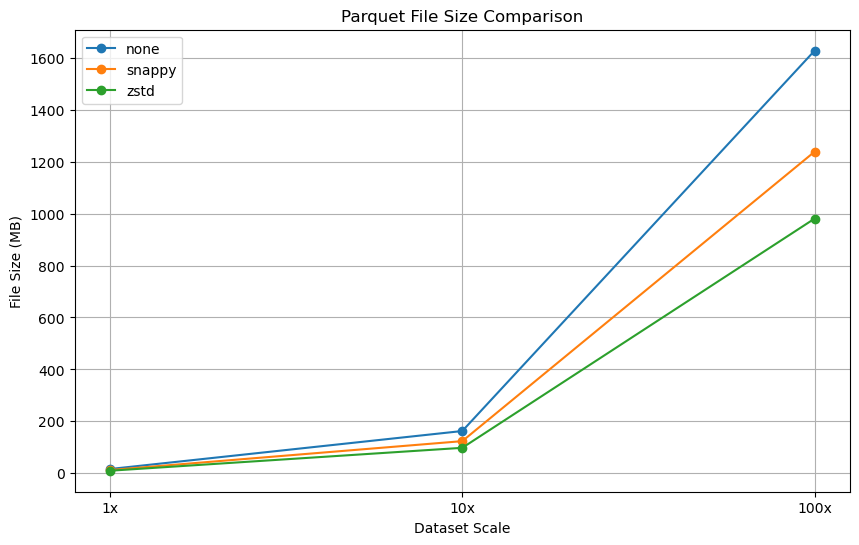

In [35]:
plt.figure(figsize=(10, 6))

for compression in ["none", "snappy", "zstd"]:

    subset = final_results[
        final_results["Compression"] == compression
    ]

    plt.plot(
        subset["Scale"],
        subset["Parquet Size (MB)"],
        marker="o",
        label=compression
    )

plt.title("Parquet File Size Comparison")
plt.xlabel("Dataset Scale")
plt.ylabel("File Size (MB)")
plt.legend()
plt.grid()
plt.show()

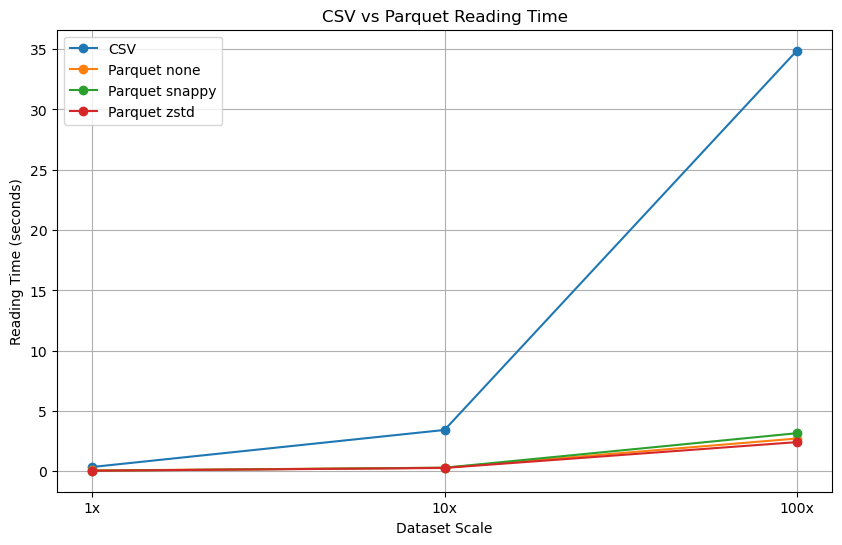

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    csv_df["Scale"],
    csv_df["CSV Read Time (seconds)"],
    marker="o",
    label="CSV"
)

for compression in ["none", "snappy", "zstd"]:

    subset = final_results[
        final_results["Compression"] == compression
    ]

    plt.plot(
        subset["Scale"],
        subset["Read Time (seconds)"],
        marker="o",
        label=f"Parquet {compression}"
    )

plt.title("CSV vs Parquet Reading Time")
plt.xlabel("Dataset Scale")
plt.ylabel("Reading Time (seconds)")
plt.legend()
plt.grid()
plt.show()

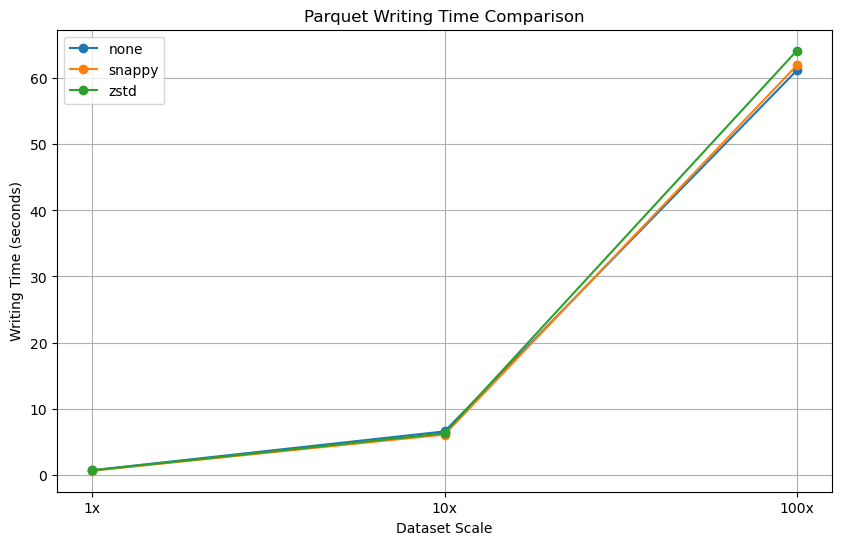

In [37]:
plt.figure(figsize=(10, 6))

for compression in ["none", "snappy", "zstd"]:

    subset = final_results[
        final_results["Compression"] == compression
    ]

    plt.plot(
        subset["Scale"],
        subset["Write Time (seconds)"],
        marker="o",
        label=compression
    )

plt.title("Parquet Writing Time Comparison")
plt.xlabel("Dataset Scale")
plt.ylabel("Writing Time (seconds)")
plt.legend()
plt.grid()
plt.show()

In [38]:
import pandas as pd
import time
import statistics
import os

csv_repeat_results = []

for scale, file in datasets.items():

    times = []

    print(f"\nTesting {scale}")

    for run in range(1, 4):

        start = time.time()

        total_rows = 0

        for chunk in pd.read_csv(file, chunksize=100000):
            total_rows += len(chunk)

        elapsed = time.time() - start

        times.append(elapsed)

        print(f"Run {run}: {elapsed:.2f} seconds")

    median_time = statistics.median(times)

    csv_repeat_results.append({
        "Scale": scale,
        "Rows": total_rows,
        "Run 1": round(times[0], 2),
        "Run 2": round(times[1], 2),
        "Run 3": round(times[2], 2),
        "Median Read Time": round(median_time, 2)
    })

csv_repeat_df = pd.DataFrame(csv_repeat_results)

display(csv_repeat_df)

csv_repeat_df.to_csv(
    "benchmarks/csv_repeated_results.csv",
    index=False
)


Testing 1x
Run 1: 0.33 seconds
Run 2: 0.32 seconds
Run 3: 0.34 seconds

Testing 10x
Run 1: 3.38 seconds
Run 2: 3.60 seconds
Run 3: 3.47 seconds

Testing 100x
Run 1: 35.47 seconds
Run 2: 33.24 seconds
Run 3: 33.44 seconds


,Scale,Rows,Run 1,Run 2,Run 3,Median Read Time
0,1x,619029,0.33,0.32,0.34,0.33
1,10x,6190290,3.38,3.60,3.47,3.47
2,100x,61902900,35.47,33.24,33.44,33.44


In [39]:

import pyarrow.parquet as pq
import pandas as pd
import time
import statistics
import os

parquet_repeat_results = []

for scale in ["1x", "10x", "100x"]:

    for compression in ["none", "snappy", "zstd"]:

        file = f"benchmarks/{scale}_{compression}.parquet"

        times = []

        print(f"\nTesting {scale} - {compression}")

        for run in range(1, 4):

            start = time.time()

            parquet_reader = pq.ParquetFile(file)

            total_rows = 0

            for batch in parquet_reader.iter_batches(
                batch_size=100000
            ):
                total_rows += batch.num_rows

            elapsed = time.time() - start

            times.append(elapsed)

            print(f"Run {run}: {elapsed:.2f} seconds")

        median_time = statistics.median(times)

        parquet_repeat_results.append({
            "Scale": scale,
            "Compression": compression,
            "Rows": total_rows,
            "Run 1": round(times[0], 2),
            "Run 2": round(times[1], 2),
            "Run 3": round(times[2], 2),
            "Median Read Time": round(median_time, 2),
            "File Size MB": round(
                os.path.getsize(file) / (1024**2), 2
            )
        })

parquet_repeat_df = pd.DataFrame(parquet_repeat_results)

display(parquet_repeat_df)

parquet_repeat_df.to_csv(
    "benchmarks/parquet_repeated_results.csv",
    index=False
)

print("\nParquet repeated benchmark completed!")



Testing 1x - none
Run 1: 0.04 seconds
Run 2: 0.03 seconds
Run 3: 0.03 seconds

Testing 1x - snappy
Run 1: 0.04 seconds
Run 2: 0.03 seconds
Run 3: 0.03 seconds

Testing 1x - zstd
Run 1: 0.05 seconds
Run 2: 0.05 seconds
Run 3: 0.06 seconds

Testing 10x - none
Run 1: 0.31 seconds
Run 2: 0.21 seconds
Run 3: 0.21 seconds

Testing 10x - snappy
Run 1: 0.37 seconds
Run 2: 0.21 seconds
Run 3: 0.24 seconds

Testing 10x - zstd
Run 1: 0.27 seconds
Run 2: 0.21 seconds
Run 3: 0.31 seconds

Testing 100x - none
Run 1: 2.82 seconds
Run 2: 2.27 seconds
Run 3: 2.13 seconds

Testing 100x - snappy
Run 1: 3.02 seconds
Run 2: 2.68 seconds
Run 3: 2.12 seconds

Testing 100x - zstd
Run 1: 2.98 seconds
Run 2: 2.74 seconds
Run 3: 2.45 seconds


,Scale,Compression,Rows,Run 1,Run 2,Run 3,Median Read Time,File Size MB
0,1x,none,619029,0.04,0.03,0.03,0.03,16.45
1,1x,snappy,619029,0.04,0.03,0.03,0.03,12.52
2,1x,zstd,619029,0.05,0.05,0.06,0.05,9.88
3,10x,none,6190290,0.31,0.21,0.21,0.21,162.74
4,10x,snappy,6190290,0.37,0.21,0.24,0.24,123.79
5,10x,zstd,6190290,0.27,0.21,0.31,0.27,98.06
6,100x,none,61902900,2.82,2.27,2.13,2.27,1627.07
7,100x,snappy,61902900,3.02,2.68,2.12,2.68,1238.14
8,100x,zstd,61902900,2.98,2.74,2.45,2.74,980.51



Parquet repeated benchmark completed!


I recommend:

Dataset

Recommended format

Reason

* - 1x

- Parquet Snappy

- Good balance of storage and reading speed

* -10x

-Parquet Zstandard

-Smallest file, reasonable reading speed

* -100x

-Parquet Zstandard

-Saves approximately 66% storage

However,if reading speed is the highest priority and storage is less important, uncompressed Parquet is the better choice at 10x and 100x.



In [40]:
comparison = parquet_repeat_df.merge(
    csv_repeat_df[["Scale", "Median Read Time"]],
    on="Scale",
    suffixes=("_Parquet", "_CSV")
)

comparison["Speedup"] = (
    comparison["Median Read Time_CSV"] /
    comparison["Median Read Time_Parquet"]
)

comparison["Storage Reduction (%)"] = (
    (
        comparison["CSV Size MB"] -
        comparison["File Size MB"]
    ) / comparison["CSV Size MB"]
) * 100

display(comparison)

comparison.to_csv(
    "benchmarks/final_comparison.csv",
    index=False
)

KeyError: 'CSV Size MB'

In [41]:
print("CSV columns:")
print(csv_repeat_df.columns.tolist())

print("\nParquet columns:")
print(parquet_repeat_df.columns.tolist())


# Get CSV file sizes directly from your original files

csv_sizes = []

for scale, file in datasets.items():

    size = os.path.getsize(file) / (1024**2)

    csv_sizes.append({
        "Scale": scale,
        "CSV Size MB": size
    })

csv_size_df = pd.DataFrame(csv_sizes)

# Merge CSV and Parquet results
comparison = parquet_repeat_df.merge(
    csv_repeat_df[["Scale", "Median Read Time"]],
    on="Scale"
)

comparison = comparison.rename(
    columns={
        "Median Read Time_x": "Parquet Median Read Time",
        "Median Read Time_y": "CSV Median Read Time"
    }
)

# Add CSV file sizes
comparison = comparison.merge(
    csv_size_df,
    on="Scale"
)

# Calculate speed improvement
comparison["Speedup"] = (
    comparison["CSV Median Read Time"] /
    comparison["Parquet Median Read Time"]
)

# Calculate storage reduction
comparison["Storage Reduction (%)"] = (
    (
        comparison["CSV Size MB"] -
        comparison["File Size MB"]
    ) / comparison["CSV Size MB"]
) * 100

# Display results
display(comparison)

# Save final results
comparison.to_csv(
    "benchmarks/final_comparison.csv",
    index=False
)

print("Final comparison saved successfully!")



CSV columns:
['Scale', 'Rows', 'Run 1', 'Run 2', 'Run 3', 'Median Read Time']

Parquet columns:
['Scale', 'Compression', 'Rows', 'Run 1', 'Run 2', 'Run 3', 'Median Read Time', 'File Size MB']


,Scale,Compression,Rows,Run 1,Run 2,Run 3,Parquet Median Read Time,File Size MB,CSV Median Read Time,CSV Size MB,Speedup,Storage Reduction (%)
0,1x,none,619029,0.04,0.03,0.03,0.03,16.45,0.33,28.800235,11.000000,42.882410
1,1x,snappy,619029,0.04,0.03,0.03,0.03,12.52,0.33,28.800235,11.000000,56.528132
2,1x,zstd,619029,0.05,0.05,0.06,0.05,9.88,0.33,28.800235,6.600000,65.694724
3,10x,none,6190290,0.31,0.21,0.21,0.21,162.74,3.47,288.002022,16.523810,43.493452
4,10x,snappy,6190290,0.37,0.21,0.24,0.24,123.79,3.47,288.002022,14.458333,57.017663
5,10x,zstd,6190290,0.27,0.21,0.31,0.27,98.06,3.47,288.002022,12.851852,65.951628
6,100x,none,61902900,2.82,2.27,2.13,2.27,1627.07,33.44,2880.019892,14.731278,43.504904
7,100x,snappy,61902900,3.02,2.68,2.12,2.68,1238.14,33.44,2880.019892,12.477612,57.009325
8,100x,zstd,61902900,2.98,2.74,2.45,2.74,980.51,33.44,2880.019892,12.204380,65.954749


Final comparison saved successfully!


# 1. the important results from  table:

 Most important findings
Storage reduction at 100x

65.95%
Using Zstandard compared with CSV

Reading speed improvement at 100x

14.73x

Storage saved at 100x

1,899.51 MB
Using Zstandard instead of CSV

One important distinction: uncompressed Parquet is fastest in  repeated reading measurements, while Zstandard provides the greatest storage savings. They are different optimization goals.

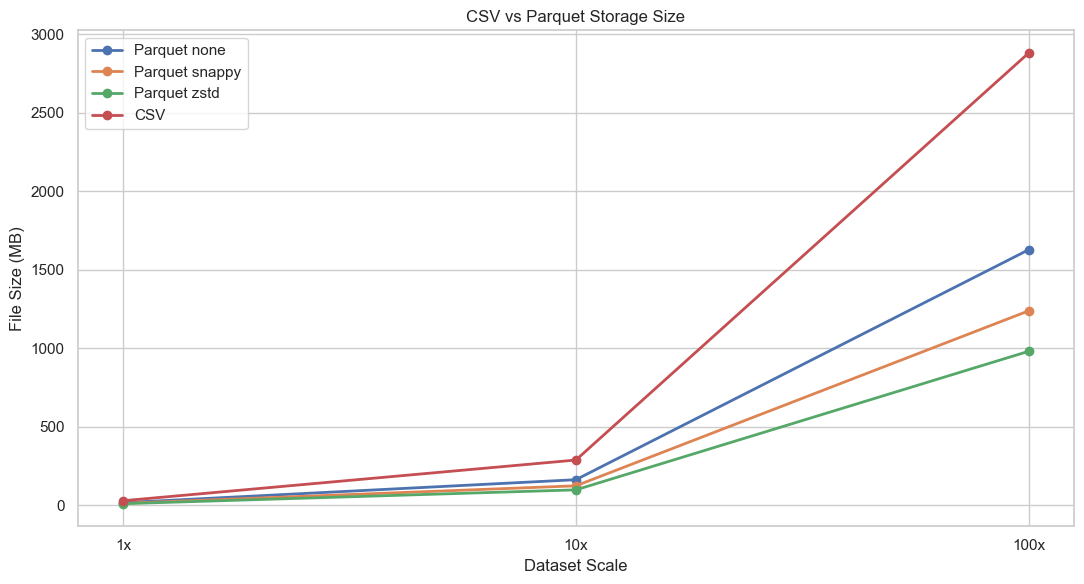

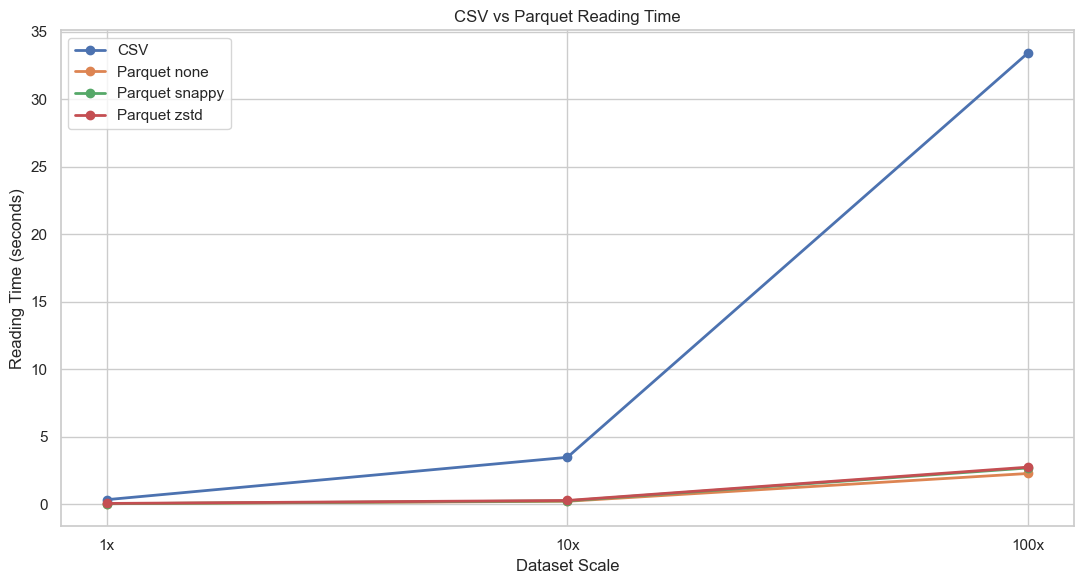

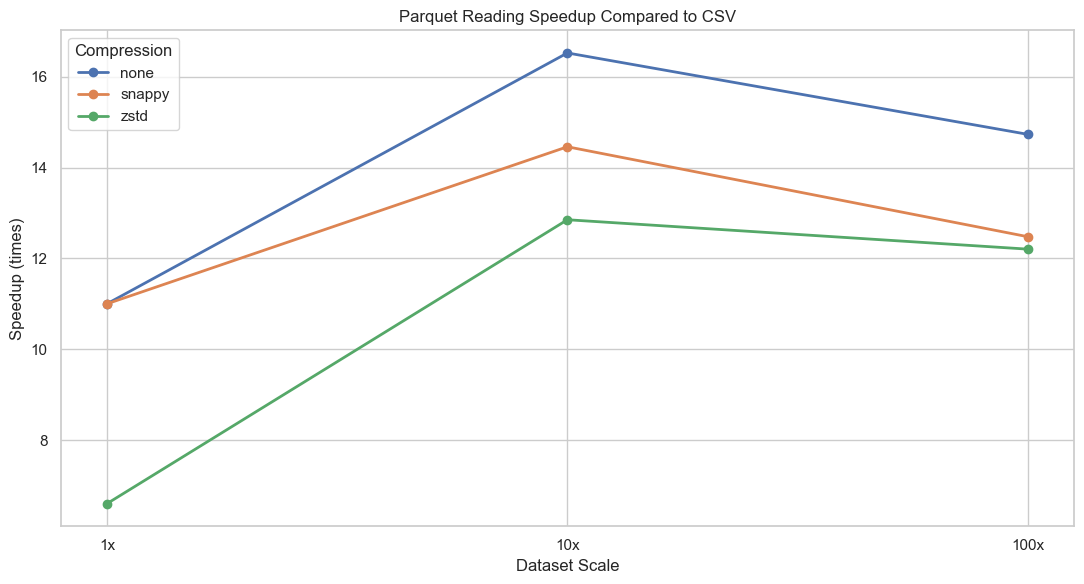

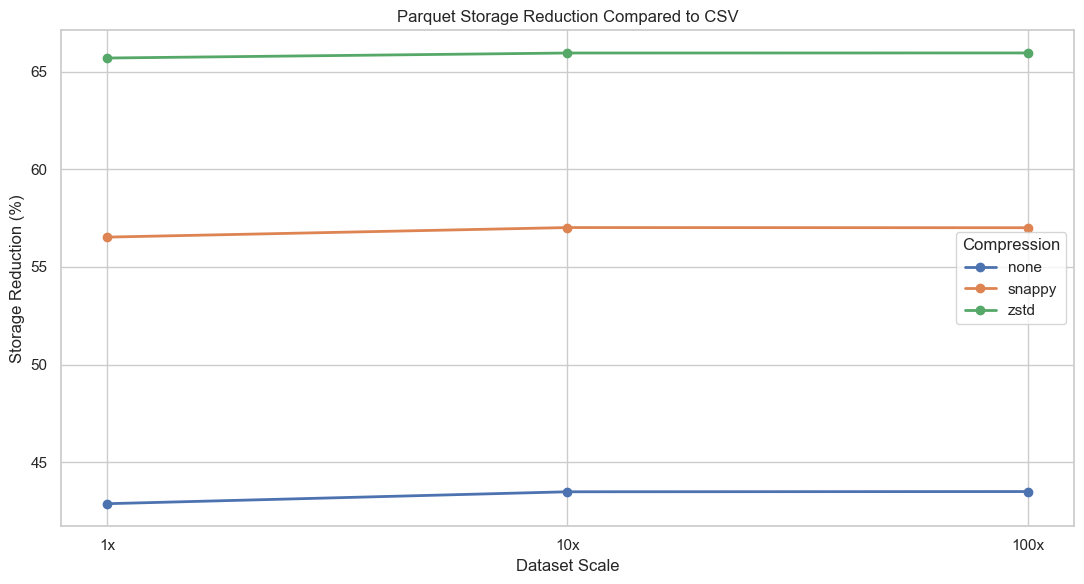

All four graphs saved successfully!


In [42]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Use the comparison results
df = comparison.copy()

os.makedirs("benchmarks/graphs", exist_ok=True)

# Graph 1: Storage comparison
plt.figure(figsize=(11, 6))

for compression in ["none", "snappy", "zstd"]:
    subset = df[df["Compression"] == compression]

    plt.plot(
        subset["Scale"],
        subset["File Size MB"],
        marker="o",
        linewidth=2,
        label=f"Parquet {compression}"
    )

plt.plot(
    ["1x", "10x", "100x"],
    [28.80, 288.00, 2880.02],
    marker="o",
    linewidth=2,
    label="CSV"
)

plt.title("CSV vs Parquet Storage Size")
plt.xlabel("Dataset Scale")
plt.ylabel("File Size (MB)")
plt.legend()
plt.tight_layout()
plt.savefig("benchmarks/graphs/storage_comparison.png")
plt.show()


# Graph 2: Reading time comparison
plt.figure(figsize=(11, 6))

plt.plot(
    ["1x", "10x", "100x"],
    [0.33, 3.47, 33.44],
    marker="o",
    linewidth=2,
    label="CSV"
)

for compression in ["none", "snappy", "zstd"]:
    subset = df[df["Compression"] == compression]

    plt.plot(
        subset["Scale"],
        subset["Parquet Median Read Time"],
        marker="o",
        linewidth=2,
        label=f"Parquet {compression}"
    )

plt.title("CSV vs Parquet Reading Time")
plt.xlabel("Dataset Scale")
plt.ylabel("Reading Time (seconds)")
plt.legend()
plt.tight_layout()
plt.savefig("benchmarks/graphs/reading_comparison.png")
plt.show()


# Graph 3: Speedup
plt.figure(figsize=(11, 6))

for compression in ["none", "snappy", "zstd"]:
    subset = df[df["Compression"] == compression]

    plt.plot(
        subset["Scale"],
        subset["Speedup"],
        marker="o",
        linewidth=2,
        label=compression
    )

plt.title("Parquet Reading Speedup Compared to CSV")
plt.xlabel("Dataset Scale")
plt.ylabel("Speedup (times)")
plt.legend(title="Compression")
plt.tight_layout()
plt.savefig("benchmarks/graphs/speedup_comparison.png")
plt.show()


# Graph 4: Storage reduction
plt.figure(figsize=(11, 6))

for compression in ["none", "snappy", "zstd"]:
    subset = df[df["Compression"] == compression]

    plt.plot(
        subset["Scale"],
        subset["Storage Reduction (%)"],
        marker="o",
        linewidth=2,
        label=compression
    )

plt.title("Parquet Storage Reduction Compared to CSV")
plt.xlabel("Dataset Scale")
plt.ylabel("Storage Reduction (%)")
plt.legend(title="Compression")
plt.tight_layout()
plt.savefig("benchmarks/graphs/storage_reduction.png")
plt.show()

print("All four graphs saved successfully!")


## Part 2 - DATA ANALYSIS & PREDICTION

In [1]:

import pandas as pd
import numpy as np
import time

# Load the original cleaned dataset
start_time = time.time()

stock_df = pd.read_csv( "all_stocks_5yr.csv")

end_time = time.time()

print("Dataset loaded successfully!")
print("Dataset shape:", stock_df.shape)
print("Loading time:", round(end_time - start_time, 4), "seconds")


Dataset loaded successfully!
Dataset shape: (619029, 7)
Loading time: 1.64 seconds


In [2]:
# EXAMINE DATASET


# Display the first five rows
display(stock_df.head())

# Check column names
print("Columns:", stock_df.columns.tolist())

# Check data types
stock_df.info()

# Check number of companies
print("Number of companies:", stock_df["name"].nunique())

# Check missing values
print(stock_df.isnull().sum())


,date,open,high,low,close,volume,name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


Columns: ['date', 'open', 'high', 'low', 'close', 'volume', 'name']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619029 entries, 0 to 619028
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619029 non-null  object 
 1   open    619029 non-null  float64
 2   high    619029 non-null  float64
 3   low     619029 non-null  float64
 4   close   619029 non-null  float64
 5   volume  619029 non-null  int64  
 6   name    619029 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB
Number of companies: 505
date      0
open      0
high      0
low       0
close     0
volume    0
name      0
dtype: int64


In [3]:

# Convert date to datetime
stock_df["date"] = pd.to_datetime(stock_df["date"])

# Sort by company and date
stock_df = stock_df.sort_values(
    by=["name", "date"]
).reset_index(drop=True)

# Verify sorting and dataset
print("Date range:")
print(stock_df["date"].min(), "to", stock_df["date"].max())

print("\nDataset shape:", stock_df.shape)

display(stock_df.head(10))


Date range:
2013-02-08 00:00:00 to 2018-02-07 00:00:00

Dataset shape: (619029, 7)


,date,open,high,low,close,volume,name
0,2013-02-08,45.07,45.35,45.000,45.08,1824755,A
1,2013-02-11,45.17,45.18,44.450,44.60,2915405,A
2,2013-02-12,44.81,44.95,44.500,44.62,2373731,A
3,2013-02-13,44.81,45.24,44.680,44.75,2052338,A
4,2013-02-14,44.72,44.78,44.360,44.58,3826245,A
5,2013-02-15,43.48,44.24,42.210,42.25,14657315,A
6,2013-02-19,42.21,43.12,42.210,43.01,4116141,A
7,2013-02-20,42.84,42.85,42.225,42.24,3873183,A
8,2013-02-21,42.14,42.14,41.470,41.63,3415149,A
9,2013-02-22,41.83,42.07,41.580,41.80,3354862,A


# Calculate technical indicators

In [5]:

# Calculate 5-day Simple Moving Average for each company
stock_df["sma_5"] = (
    stock_df.groupby("name")["close"]
    .transform(lambda x: x.rolling(window=5).mean())
)

# Display results
display(stock_df[["date", "name", "close", "sma_5"]].head(10))


,date,name,close,sma_5
0,2013-02-08,A,45.08,NaN
1,2013-02-11,A,44.60,NaN
2,2013-02-12,A,44.62,NaN
3,2013-02-13,A,44.75,NaN
4,2013-02-14,A,44.58,44.726
5,2013-02-15,A,42.25,44.160
6,2013-02-19,A,43.01,43.842
7,2013-02-20,A,42.24,43.366
8,2013-02-21,A,41.63,42.742
9,2013-02-22,A,41.80,42.186


In [6]:

# Calculate daily price changes for each company
price_change = stock_df.groupby("name")["close"].diff()

# Separate gains and losses
gain = price_change.clip(lower=0)
loss = -price_change.clip(upper=0)

# Calculate 14-period exponentially smoothed average gains and losses
avg_gain = gain.groupby(stock_df["name"]).transform(
    lambda x: x.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
)

avg_loss = loss.groupby(stock_df["name"]).transform(
    lambda x: x.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
)

# Calculate RSI
relative_strength = avg_gain / avg_loss

stock_df["rsi_14"] = 100 - (100 / (1 + relative_strength))

# Display results
display(stock_df[["date", "name", "close", "rsi_14"]].head(25))


,date,name,close,rsi_14
0,2013-02-08,A,45.08,NaN
1,2013-02-11,A,44.60,NaN
2,2013-02-12,A,44.62,NaN
3,2013-02-13,A,44.75,NaN
4,2013-02-14,A,44.58,NaN
5,2013-02-15,A,42.25,NaN
6,2013-02-19,A,43.01,NaN
7,2013-02-20,A,42.24,NaN
8,2013-02-21,A,41.63,NaN
9,2013-02-22,A,41.80,NaN


In [7]:

print("Updated dataset shape:", stock_df.shape)

print("\nNew columns:")
print(stock_df.columns.tolist())

print("\nMissing values in technical indicators:")
print(stock_df[["sma_5", "rsi_14"]].isnull().sum())

print("\nTechnical indicator statistics:")
display(stock_df[["sma_5", "rsi_14"]].describe())


Updated dataset shape: (619029, 9)

New columns:
['date', 'open', 'high', 'low', 'close', 'volume', 'name', 'sma_5', 'rsi_14']

Missing values in technical indicators:
sma_5     2020
rsi_14    7070
dtype: int64

Technical indicator statistics:


,sma_5,rsi_14
count,617009.000000,611959.000000
mean,83.042523,52.903580
std,97.330479,12.154140
min,1.692000,1.085165
25%,40.264000,44.483132
50%,62.640000,53.271870
75%,94.374000,61.575510
max,2034.752000,94.330123


###  Technical Indicators

Technical indicators are mathematical calculations based on historical stock prices and trading volumes. They help identify price trends and market momentum.

Two technical indicators were selected for this analysis:

- **Simple Moving Average (SMA 5):** Calculates the average closing price over five trading days to identify short-term price trends.
- **Relative Strength Index (RSI 14):** Measures the strength of recent price movements over 14 periods. Values above 70 generally indicate potentially overbought conditions, while values below 30 may indicate potentially oversold conditions.

### Interpretation of Technical Indicators

The calculations successfully added two new columns, SMA 5 and RSI 14, increasing the dataset from seven to nine columns.

The SMA 5 calculation produced 2,020 missing values, while RSI 14 produced 7,070 missing values. These missing values are expected because each indicator requires a minimum number of historical observations.

The average RSI was approximately 52.90, suggesting relatively neutral price momentum across the dataset.

### Comparing Pandas and Polars

Pandas and Polars are Python libraries used for data manipulation and analysis. This section compares their performance when loading, sorting, and calculating technical indicators using the original 1x stock dataset.

In [9]:
try:
    import polars as pl
    print("Polars version:", pl.__version__)

except ImportError:
    print("Polars is not installed. Run: %pip install polars")

Polars version: 2.1.0


In [11]:
start_time = time.time()

pandas_df = pd.read_csv("all_stocks_5yr.csv")

pandas_df["date"] = pd.to_datetime(pandas_df["date"])

pandas_df = pandas_df.sort_values(
    by=["name", "date"]
).reset_index(drop=True)

# Calculate SMA (5-day)
pandas_df["sma_5"] = (
    pandas_df.groupby("name")["close"]
    .transform(lambda x: x.rolling(window=5).mean())
)

# Calculate RSI (14-day)
price_change = pandas_df.groupby("name")["close"].diff()

gain = price_change.clip(lower=0)
loss = -price_change.clip(upper=0)

avg_gain = gain.groupby(pandas_df["name"]).transform(
    lambda x: x.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
)

avg_loss = loss.groupby(pandas_df["name"]).transform(
    lambda x: x.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
)

pandas_df["rsi_14"] = 100 - (100 / (1 + avg_gain / avg_loss))

pandas_time = time.time() - start_time

print("Pandas processing time:", round(pandas_time, 3), "seconds")
print("Dataset shape:", pandas_df.shape)

Pandas processing time: 3.107 seconds
Dataset shape: (619029, 9)


In [12]:
start_time = time.time()

polars_df = pl.read_csv("all_stocks_5yr.csv")

polars_df = polars_df.with_columns(
    pl.col("date").str.to_datetime()
)

polars_df = polars_df.sort(["name", "date"])

# Calculate SMA (5-day)
polars_df = polars_df.with_columns(
    pl.col("close")
    .rolling_mean(window_size=5)
    .over("name")
    .alias("sma_5")
)

# Calculate RSI (14-day)
polars_df = polars_df.with_columns(
    pl.col("close").diff().over("name").alias("price_change")
)

polars_df = polars_df.with_columns([
    pl.col("price_change").clip(lower_bound=0).alias("gain"),
    (-pl.col("price_change")).clip(lower_bound=0).alias("loss")
])

polars_df = polars_df.with_columns([
    pl.col("gain").ewm_mean(
        alpha=1/14, min_samples=14, adjust=False
    ).over("name").alias("avg_gain"),

    pl.col("loss").ewm_mean(
        alpha=1/14, min_samples=14, adjust=False
    ).over("name").alias("avg_loss")
])

polars_df = polars_df.with_columns(
    (100 - (100 / (1 + pl.col("avg_gain") / pl.col("avg_loss"))))
    .alias("rsi_14")
)

polars_time = time.time() - start_time

print("Polars processing time:", round(polars_time, 3), "seconds")
print("Dataset shape:", polars_df.shape)

Polars processing time: 1.056 seconds
Dataset shape: (619029, 14)


In [13]:
# Remove intermediate calculation columns from Polars
polars_df = polars_df.drop([
    "price_change",
    "gain",
    "loss",
    "avg_gain",
    "avg_loss"
])

print("Pandas shape:", pandas_df.shape)
print("Polars shape:", polars_df.shape)

print("\nPolars columns:")
print(polars_df.columns)

Pandas shape: (619029, 9)
Polars shape: (619029, 9)

Polars columns:
['date', 'open', 'high', 'low', 'close', 'volume', 'name', 'sma_5', 'rsi_14']


### Pandas vs. Polars Performance

Polars processed the original stock dataset in 1.056 seconds, 
while Pandas took 3.107 seconds. This means Polars was 
approximately 2.94 times faster in this test.

Both libraries successfully processed the 619,029-row dataset 
and calculated the technical indicators. Polars demonstrated 
better processing speed, making it a potentially more efficient 
choice for larger datasets.

### Machine Learning Model Development

Two regression algorithms, Linear Regression and Random Forest 
Regression, will be used to predict the next trading day's 
closing price.

The dataset will be divided chronologically, using the first 
80% of observations for training and the final 20% for testing. 
This approach prevents future observations from being used to 
predict past stock prices.

In [14]:
# Create a copy for machine learning
model_df = pandas_df.copy()

# Create the next day's closing price for each company
model_df["next_close"] = (
    model_df.groupby("name")["close"].shift(-1)
)

# Remove rows without a next-day closing price
model_df = model_df.dropna().reset_index(drop=True)

# Display the dataset
print("Dataset shape:", model_df.shape)
print(model_df.head())

Dataset shape: (611454, 10)
        date   open   high    low  close   volume name   sma_5     rsi_14  \
0 2013-03-01  41.18  41.98  40.73  41.93  3089323    A  41.480  23.511622   
1 2013-03-04  41.75  42.18  41.52  42.03  2435306    A  41.628  24.628635   
2 2013-03-05  42.35  43.19  42.34  42.66  3289188    A  41.966  31.423247   
3 2013-03-06  43.00  43.52  42.90  43.24  2996908    A  42.268  37.049623   
4 2013-03-07  43.30  43.48  42.81  43.25  2414186    A  42.622  37.145374   

   next_close  
0       42.03  
1       42.66  
2       43.24  
3       43.25  
4       43.03  


### Feature Selection

The following variables will be used as predictors:

- open: Opening stock price.
- high: Highest stock price during the trading day.
- low: Lowest stock price during the trading day.
- close: Current closing stock price.
- volume: Number of shares traded.
- sma_5: Five-day simple moving average.
- rsi_14: Fourteen-day relative strength index.

The target variable is next_close, representing the next trading day's closing price. The company name and date are excluded from the initial numerical feature set.

In [15]:
# Select input features
features = [
    "open",
    "high",
    "low",
    "close",
    "volume",
    "sma_5",
    "rsi_14"
]

X = model_df[features]
y = model_df["next_close"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing values:")
print(X.isnull().sum())
print("\nTarget missing values:", y.isnull().sum())

Features shape: (611454, 7)
Target shape: (611454,)

Missing values:
open      0
high      0
low       0
close     0
volume    0
sma_5     0
rsi_14    0
dtype: int64

Target missing values: 0


In [16]:
# Find the chronological split point
split_index = int(len(model_df) * 0.8)

# Split the features and target
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining date range:")
print(model_df["date"].iloc[:split_index].min(),
      "to",
      model_df["date"].iloc[:split_index].max())

print("\nTesting date range:")
print(model_df["date"].iloc[split_index:].min(),
      "to",
      model_df["date"].iloc[split_index:].max())

Training rows: 489163
Testing rows: 122291

Training date range:
2013-03-01 00:00:00 to 2018-02-06 00:00:00

Testing date range:
2013-03-01 00:00:00 to 2018-02-06 00:00:00


In [17]:
# Get all unique trading dates in chronological order
unique_dates = sorted(model_df["date"].unique())

# Find the date representing the 80% cutoff
split_date_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_date_index]

print("Chronological cutoff date:", split_date)
print("Total unique trading dates:", len(unique_dates))

Chronological cutoff date: 2017-02-10 00:00:00
Total unique trading dates: 1244


In [18]:
# Training: dates before the cutoff
train_data = model_df[model_df["date"] < split_date]

# Testing: dates on or after the cutoff
test_data = model_df[model_df["date"] >= split_date]

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data["next_close"]
y_test = test_data["next_close"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining date range:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nTesting date range:")
print(test_data["date"].min(), "to", test_data["date"].max())

Training rows: 486367
Testing rows: 125087

Training date range:
2013-03-01 00:00:00 to 2017-02-09 00:00:00

Testing date range:
2017-02-10 00:00:00 to 2018-02-06 00:00:00


### Training and Testing Data Split

The dataset was divided chronologically using an 80/20 split based on unique trading dates. The training set contains 486,367 observations from March 1, 2013, to February 9, 2017. The testing set contains 125,087 observations from February 10, 2017, to February 6, 2018.

This approach ensures that historical observations are used to train the models and later observations are used to evaluate their predictive performance.

### Model 1: Linear Regression

Linear Regression is used as the baseline prediction model. It estimates the next day's closing price by identifying linear relationships between the selected stock features and the target variable.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Create the Linear Regression model
lr_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train the model
start_time = time.time()

lr_model.fit(X_train, y_train)

lr_training_time = time.time() - start_time

# Make predictions
lr_predictions = lr_model.predict(X_test)

# Evaluate the model
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("-------------------------")
print("Training time:", round(lr_training_time, 2), "seconds")
print("MAE:", round(lr_mae, 4))
print("RMSE:", round(lr_rmse, 4))
print("R-squared:", round(lr_r2, 4))

Linear Regression Results
-------------------------
Training time: 0.35 seconds
MAE: 0.9039
RMSE: 2.2239
R-squared: 0.9997


### Model 2: Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines multiple decision trees to make predictions. It can capture nonlinear relationships between stock market variables and the next day's closing price.

In [20]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("Training time:", round(rf_training_time, 2), "seconds")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R-squared:", round(rf_r2, 4))

Random Forest Results
---------------------
Training time: 404.52 seconds
MAE: 1.378
RMSE: 10.2741
R-squared: 0.9935


In [21]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "Training Time (seconds)": [lr_training_time, rf_training_time],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R-squared": [lr_r2, rf_r2]
})

results

,Model,Training Time (seconds),MAE,RMSE,R-squared
0,Linear Regression,0.347382,0.903932,2.223897,0.999696
1,Random Forest,404.523637,1.378028,10.274120,0.993505


### Model Performance Comparison

Linear Regression outperformed Random Forest across all three evaluation metrics. It achieved a lower MAE of 0.9039 compared to 1.3780 and a lower RMSE of 2.2239 compared to 10.2741. It also achieved a higher R-squared of 0.9997.

Linear Regression was substantially faster, requiring only 0.35 seconds to train compared to 404.52 seconds for Random Forest.

Based on these results, Linear Regression was the better-performing model for this experiment. However, the high R-squared values should be interpreted cautiously because current closing prices are strongly related to next-day closing prices.

In [22]:
# Baseline: predict that next day's close equals today's close
baseline_predictions = X_test["close"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Results")
print("----------------")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R-squared:", round(baseline_r2, 4))

Baseline Results
----------------
MAE: 0.9044
RMSE: 2.225
R-squared: 0.9997


### Baseline Model Comparison

A baseline model was created by assuming that the next day's closing price would equal the current day's closing price.

The baseline achieved an MAE of 0.9044 and an RMSE of 2.2250. Linear Regression performed only slightly better, with an MAE of 0.9039 and an RMSE of 2.2239. Random Forest performed worse, with an MAE of 1.3780 and an RMSE of 10.2741.

These results indicate that Linear Regression provides only a marginal improvement over the baseline. The high R-squared values should therefore not be interpreted as evidence of strong predictive ability.

## Part 3: Interactive Stock Prediction Dashboard

The final part of the project involves developing an interactive dashboard using Streamlit. The dashboard will allow users to select individual companies, explore historical stock prices, and compare actual and predicted next-day closing prices.

In [23]:
# Create a results dataframe for the test dataset
prediction_results = test_data[
    ["date", "name", "close", "next_close"]
].copy()

# Add predictions from both models and the baseline
prediction_results["linear_regression"] = lr_predictions
prediction_results["random_forest"] = rf_predictions
prediction_results["baseline"] = X_test["close"].values

# Display the results
print(prediction_results.head())

print("\nDataset shape:", prediction_results.shape)

          date name  close  next_close  linear_regression  random_forest  \
995 2017-02-10    A  50.36       50.52          50.325239      50.532000   
996 2017-02-13    A  50.52       50.39          50.498768      50.508750   
997 2017-02-14    A  50.39       51.62          50.381698      50.608279   
998 2017-02-15    A  51.62       50.84          51.576923      51.709446   
999 2017-02-16    A  50.84       51.63          50.800722      51.030220   

     baseline  
995     50.36  
996     50.52  
997     50.39  
998     51.62  
999     50.84  

Dataset shape: (125087, 7)


### Saving Prediction Results

The predictions from Linear Regression, Random Forest, and the baseline model are saved to a CSV file. This file will serve as the data source for the interactive Streamlit dashboard.

In [24]:
# Save prediction results
prediction_results.to_csv(
    "stock_prediction_results.csv",
    index=False
)

print("Prediction results saved successfully.")

Prediction results saved successfully.


In [25]:
%pip install streamlit plotly

Note: you may need to restart the kernel to use updated packages.


In [26]:
import streamlit as st
import plotly.express as px

print("Streamlit version:", st.__version__)
print("Plotly version:", px.__version__ if hasattr(px, "__version__") else "Installed")

Streamlit version: 1.51.0
Plotly version: Installed


In [27]:
dataset_df = dataset_df.drop(columns=["next_close"])

dataset_df.to_csv("stock_data_with_indicators.csv", index=False)

print("Processed dataset saved successfully!")

NameError: name 'dataset_df' is not defined

In [28]:
%whos

Variable                Type                     Data/Info
----------------------------------------------------------
LinearRegression        ABCMeta                  <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor   ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
StandardScaler          type                     <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                       DataFrame                Shape: (611454, 7)
X_test                  DataFrame                Shape: (125087, 7)
X_train                 DataFrame                Shape: (486367, 7)
avg_gain                Series                   Shape: (619029,)
avg_loss                Series                   Shape: (619029,)
baseline_mae            float                    0.9043894633335199
baseline_predictions    Series                   Shape: (125087,)
baseline_r2             float                    0.9996953931584244
baseline_rmse           float

In [29]:
stock_df.to_csv("stock_data_with_indicators.csv", index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!
